### LAB ASSIGNMENT

Name: Joseph Atem Deng Aruei

Nim: 244107020242

load the CSV

In [3]:
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv('CC_Customer_Dataset.csv')

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Dataset shape: (660, 7)
Columns: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  


Scatterplot and linearity check

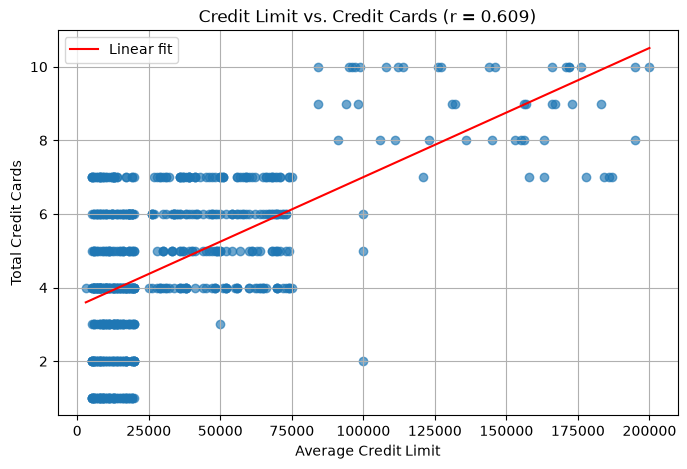

Pearson correlation: 0.609
Interpretation: moderately positive association; the points do not lie on one straight line.


In [4]:
# %%
x_col = "Avg_Credit_Limit"
y_col = "Total_Credit_Cards"

x = df[x_col].to_numpy()
y = df[y_col].to_numpy()
correlation = np.corrcoef(x, y)[0, 1]

slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.65)
plt.plot(x_line, slope * x_line + intercept, color="red", label="Linear fit")
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.title(f"Credit Limit vs. Credit Cards (r = {correlation:.3f})")
plt.legend()
plt.grid(True)
plt.show()

print(f"Pearson correlation: {correlation:.3f}")
print("Interpretation: moderately positive association; the points do not lie on one straight line.")

Scale the usable features and plot the K-Means elbow

d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

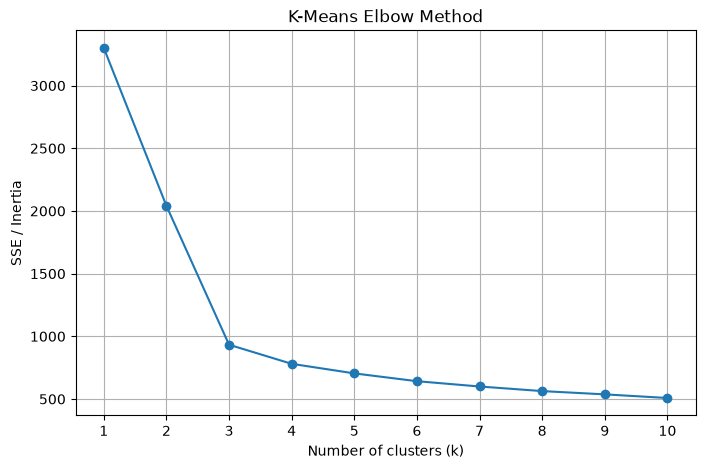

k=1: SSE=3300.00
k=2: SSE=2040.99
k=3: SSE=933.04
k=4: SSE=780.77
k=5: SSE=704.48
k=6: SSE=642.15
k=7: SSE=599.93
k=8: SSE=563.23
k=9: SSE=537.14
k=10: SSE=508.16
Rationale: the SSE falls sharply up to about k=3, then decreases more gradually.


In [5]:
# %%
feature_columns = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made",
]

X = df[feature_columns].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = range(1, 11)
sse = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    model.fit(X_scaled)
    sse.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), sse, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("SSE / Inertia")
plt.title("K-Means Elbow Method")
plt.grid(True)
plt.show()

for k, value in zip(k_values, sse):
    print(f"k={k}: SSE={value:.2f}")

selected_k = 3
print("Rationale: the SSE falls sharply up to about k=3, then decreases more gradually.")

Fit K-Means and plot the clusters

d:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


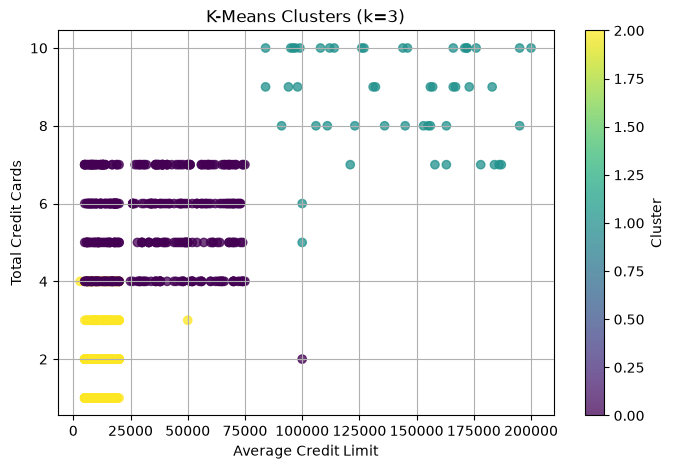

Customers per K-Means cluster:
KMeans_Cluster
0    386
1     50
2    224
Name: count, dtype: int64


In [6]:
# %%
kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=20)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
points = plt.scatter(
    df["Avg_Credit_Limit"],
    df["Total_Credit_Cards"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.75,
)
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.title(f"K-Means Clusters (k={selected_k})")
plt.colorbar(points, label="Cluster")
plt.grid(True)
plt.show()

print("Customers per K-Means cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())

State the elbow result for question 5

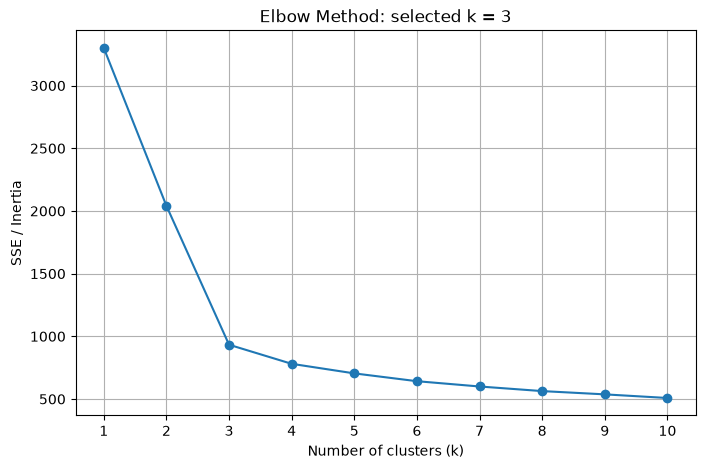

Selected K-Means k=3: the curve bends around 3, after which SSE reductions are smaller.
DBSCAN does not use k.


In [7]:
# %%
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), sse, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("SSE / Inertia")
plt.title("Elbow Method: selected k = 3")
plt.grid(True)
plt.show()

print("Selected K-Means k=3: the curve bends around 3, after which SSE reductions are smaller.")
print("DBSCAN does not use k.")

Running DBSCAN using all five usable features

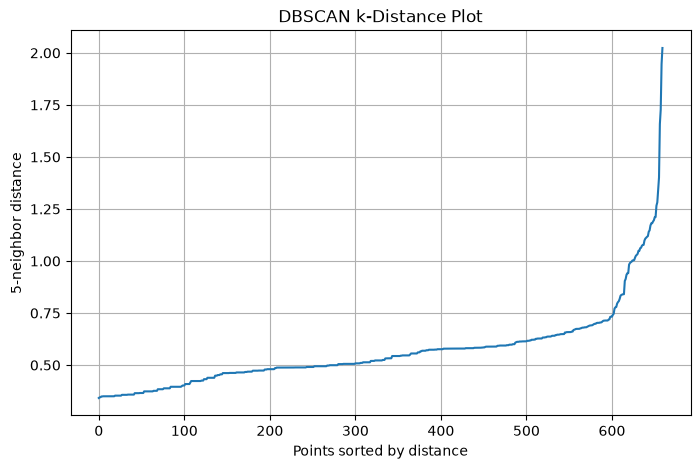

DBSCAN counts (-1 indicates noise):
DBSCAN_Cluster
-1     44
 0    606
 1     10
Name: count, dtype: int64
Number of clusters, excluding noise: 2
Number of noise points: 44


In [8]:
# %%
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples}-neighbor distance")
plt.title("DBSCAN k-Distance Plot")
plt.grid(True)
plt.show()

# Use eps=0.8 and min_samples=5 for this dataset
dbscan = DBSCAN(eps=0.8, min_samples=min_samples)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN counts (-1 indicates noise):")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

labels = df["DBSCAN_Cluster"].to_numpy()
print("Number of clusters, excluding noise:", len(set(labels) - {-1}))
print("Number of noise points:", int(np.sum(labels == -1)))

Calculate DBSCAN silhouette score and DBI

In [9]:
# %%
labels = df["DBSCAN_Cluster"].to_numpy()
non_noise = labels != -1
labels_without_noise = labels[non_noise]
X_without_noise = X_scaled[non_noise]

if len(set(labels_without_noise)) >= 2:
    silhouette = silhouette_score(X_without_noise, labels_without_noise)
    dbi = davies_bouldin_score(X_without_noise, labels_without_noise)

    print(f"Silhouette score (excluding noise): {silhouette:.3f}")
    print(f"Davies-Bouldin Index (excluding noise): {dbi:.3f}")
    print("Noise points excluded:", int((~non_noise).sum()))
else:
    print("Cannot calculate these metrics: fewer than two non-noise clusters were found.")

Silhouette score (excluding noise): 0.545
Davies-Bouldin Index (excluding noise): 0.515
Noise points excluded: 44
